# 01 — Data Ingestion & Data Quality

**Phase 1/7 — Setup & data ingestion.** Sebelum menghitung korelasi apa pun, kita pastikan datanya layak: kapan tiap seri mulai tersedia, apakah ada bulan yang bolong, dan apakah ada harga yang salah (*bad tick*). Korelasi Pearson sangat sensitif ke outlier, jadi satu harga salah bisa menenggelamkan ratusan hari normal; tahap ini mencegah kesimpulan yang sebenarnya artefak data.

Notebook ini menghasilkan:
1. Keputusan periode analisis: mulai 2007 (GFC 2008 tercakup) atau fallback ke 2010.
2. Laporan kualitas data untuk 10 seri Core, IHSG, dan alat bantu (EIDO).
3. Daftar gerakan besar dan dugaan bad tick, dengan ambang per kategori.
4. Sanity check data Yahoo terhadap angka referensi IHSG 2008.
5. Keputusan modul gap pembukaan & intraday berdasarkan kualitas data Open ^JKSE.
6. File hasil di `reports/phase1/` yang dibaca Phase 2.

Semua logika ada di `src/`; notebook ini hanya memanggil fungsi dan menampilkan hasil.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

from src import plots
from src import quality as q
from src.config import PROJECT_ROOT, load_config, output_dir, sanity_ref, series_table, target_ticker
from src.data_loader import load_prices

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

cfg = load_config()
qcfg = cfg["quality"]
series = series_table(cfg, groups=("target", "core", "tools"))
target_id, label = cfg["project"]["target_id"], target_ticker(cfg)   # ganti target lewat project.target_id
series[["id", "ticker", "name", "group", "category", "session", "transform", "override", "status"]]

,id,ticker,name,group,category,session,transform,override,status
0,JKSE,^JKSE,IHSG,target,index,target,log,False,
1,STI,^STI,Straits Times,core,index,sync,log,False,
2,KLCI,^KLSE,KLCI Malaysia,core,index,sync,log,False,
3,EEM,EEM,iShares MSCI EM,core,etf,after,log,False,
4,SPX,^GSPC,S&P 500,core,index,after,log,False,
5,NIFTY,^NSEI,Nifty 50,core,index,after,log,False,
6,HSI,^HSI,Hang Seng,core,index,sync,log,True,
7,VIX,^VIX,VIX,core,sentiment,after,log,False,
8,COPPER,HG=F,Tembaga,core,commodity,after,log,False,
9,BRENT,BZ=F,Brent,core,commodity,after,log,True,


## 1. Download data (dengan cache)

Run pertama mendownload semua seri dari Yahoo Finance (±1–2 menit) dan menyimpannya di `data/raw/` sebagai parquet. Run berikutnya memakai cache, kecuali periode yang diminta lebih panjang atau cache sudah lebih dari 7 hari. Set `REFRESH = True` untuk memaksa download ulang. Folder `data/` tidak di-commit; siapa pun bisa mereproduksinya dengan menjalankan sel ini.

In [2]:
REQUESTED_START = pd.Timestamp(cfg["project"]["start_date"])
REFRESH = False

prices = load_prices(series["ticker"].tolist(), start=REQUESTED_START,
                     end=cfg["project"]["end_date"], refresh=REFRESH)
tgt = prices[label]
print(f"{label}: {len(tgt):,} baris, {tgt.index.min():%d %b %Y} s/d {tgt.index.max():%d %b %Y}")

Cache: 12 | Download baru: 0 | Gagal: 0
^JKSE: 4,798 baris, 02 Jan 2007 s/d 21 Oct 2026


## 2. Periode analisis: 2007 atau fallback 2010?

Aturannya: periode 2007 dipakai hanya kalau ^JKSE sudah tersedia sejak awal 2007 **dan** tahun 2007–2009 masing-masing punya minimal 200 hari bursa. Kalau tidak, fallback ke 1 Januari 2010.

Catatan: ini hanya menentukan periode **analisis** (terutama untuk regime di Phase 5). Screening untuk memilih seri tetap dikunci di 2010–2019.

In [3]:
start_decision = q.decide_start(tgt["Close"], cfg["project"]["start_date"], cfg["project"]["fallback_start"],
                                qcfg["min_obs_per_year"], qcfg["start_tolerance_days"], label=label)
display(Markdown(f"**Keputusan:** {start_decision['reason']}"))
q.yearly_counts(tgt["Close"]).to_frame("hari bursa").T

**Keputusan:** ^JKSE tersedia sejak 02 Jan 2007 dan 2007-2009 lengkap -> analisis mulai 01 Jan 2007 (GFC 2008 tercakup)

Date,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
hari bursa,246,236,240,245,247,246,244,242,244,246,239,240,245,242,247,246,239,237,236


## 3. Kualitas data per seri

Kolom yang perlu diperhatikan:
- `first_date`: tanggal mulai data. EIDO memang baru listing Mei 2010.
- `min_obs_year` / `min_obs_year_at`: jumlah observasi tahun terendah (tahun penuh saja). Normalnya ±240–250 untuk bursa, ±260 untuk FX.
- `max_gap_days`: jeda kalender terpanjang. Libur Lebaran atau Imlek wajar sampai ±10 hari; di atas 14 hari ditandai.
- `pct_zero`: persentase hari dengan return tepat nol. Tinggi = indikasi harga basi.
- `n_large` / `n_bad_tick`: lihat bagian 4.

In [4]:
quality = q.quality_report(prices, series, REQUESTED_START, qcfg)
quality_view = quality.drop(columns=["name", "category", "session", "max_gap_end"]).assign(
    first_date=quality["first_date"].dt.date, last_date=quality["last_date"].dt.date, pct_zero=quality["pct_zero"].round(2))
quality_view

,id,ticker,group,first_date,last_date,n_obs,min_obs_year,min_obs_year_at,max_gap_days,pct_zero,n_large,n_bad_tick,status
0,JKSE,^JKSE,target,2007-01-02,2026-10-21,4798,236,2008,12,0.02,1,0,OK
1,STI,^STI,core,2007-01-03,2026-10-21,4951,246,2011,6,0.06,0,0,OK
2,KLCI,^KLSE,core,2007-01-03,2026-10-21,4854,242,2018,6,0.06,0,0,OK
3,EEM,EEM,core,2007-01-03,2026-10-20,4981,250,2012,5,0.68,9,3,3 dugaan bad tick
4,SPX,^GSPC,core,2007-01-03,2026-10-20,4981,250,2012,5,0.04,1,0,OK
5,NIFTY,^NSEI,core,2007-09-17,2026-10-21,4684,240,2014,6,0.09,3,0,mulai 2007-09-17
6,HSI,^HSI,core,2007-01-02,2026-10-21,4875,243,2023,6,0.00,4,1,1 dugaan bad tick
7,VIX,^VIX,core,2007-01-03,2026-10-21,4984,250,2012,5,0.38,1,0,OK
8,COPPER,HG=F,core,2007-01-01,2026-10-21,4983,250,2012,5,0.54,1,0,OK
9,BRENT,BZ=F,core,2007-07-30,2026-10-21,4787,234,2009,17,0.54,2,0,mulai 2007-07-30; gap 17 hari s/d 2009-05-01


## 4. Gerakan besar & dugaan bad tick

Ambang |return harian| dibuat per kategori. VIX memang sering bergerak >15% sehari, jadi ambangnya jauh lebih tinggi supaya tidak jadi *false positive*. Yield memakai selisih poin persen.

Gerakan besar ditandai sebagai **dugaan bad tick** kalau besoknya dibalik minimal 50% ke arah sebaliknya. Ini pola khas harga yang salah satu hari, misalnya USD/IDR yang "melonjak 15%" lalu kembali normal. Gerakan besar yang bertahan (crash nyata) tidak ditandai.

Di Phase 1 ini kita hanya **menandai**. Pembersihan dilakukan di Phase 2 dengan aturan yang sudah dikunci di README.

In [5]:
moves = q.moves_table(prices, series, qcfg)
thresholds = pd.Series(qcfg["spike_threshold"], name="ambang |return|")
counts = (moves.assign(bad_tick=moves["bad_tick"].astype(bool))
               .groupby("id").agg(gerakan_besar=("ret", "size"), dugaan_bad_tick=("bad_tick", "sum")))
display(thresholds.to_frame().T)
counts.reindex(series["id"]).fillna(0).astype(int)

,index,etf,fx,sentiment,macro,commodity,stock
ambang |return|,0.12,0.12,0.05,0.6,0.4,0.2,0.25


,gerakan_besar,dugaan_bad_tick
id,,
JKSE,1,0
STI,0,0
KLCI,0,0
EEM,9,3
SPX,1,0
NIFTY,3,0
HSI,4,1
VIX,1,0
COPPER,1,0


In [6]:
moves[moves["bad_tick"].astype(bool)].round({"ret": 4, "next_ret": 4}).head(40)

,id,category,Date,ret,next_ret,bad_tick
3,EEM,etf,2008-09-29,-0.1242,0.0779,True
9,EEM,etf,2008-11-13,0.1297,-0.1009,True
11,EEM,etf,2020-03-16,-0.1333,0.0667,True
13,EIDO,etf,2020-03-12,-0.1401,0.0711,True
17,HSI,index,2008-10-27,-0.1358,0.1341,True
29,USDIDR,fx,2010-11-01,-2.3074,2.3055,True
31,USDIDR,fx,2012-02-07,-2.3035,2.3037,True
33,USDIDR,fx,2013-10-14,-0.0608,0.0497,True
34,USDIDR,fx,2013-10-28,-0.1464,0.1371,True
36,USDIDR,fx,2013-11-11,-0.1673,0.1821,True


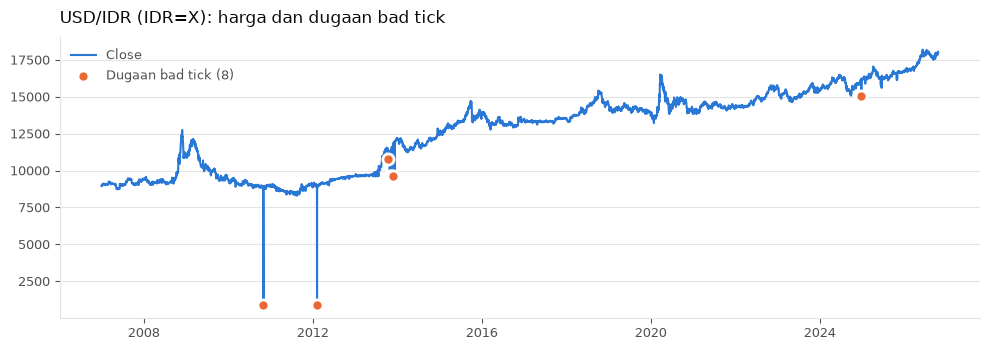

In [7]:
idr = series.set_index("id").loc[cfg["usdidr_retest"]["id"]]
fig = plots.plot_flagged_moves(prices[idr["ticker"]]["Close"], moves[moves["id"] == idr.name].set_index("Date"),
                               f"{idr['name']} ({idr['ticker']}): harga dan dugaan bad tick")

## 5. Sanity check IHSG 2008

Data Yahoo dibandingkan dengan angka referensi IHSG 2008: puncak 9 Jan, dasar 28 Okt, dua penurunan harian ±10% di 6 dan 8 Okt, serta hari suspend BEI 9–10 Okt. Hari suspend harus **tidak ada** di data (diperlakukan sebagai libur). Kalau Yahoo mengisinya dengan harga kemarin, statusnya WARN dan barisnya dibuang di Phase 2.

FAIL berarti salah satu sisi (data Yahoo atau angka referensi) perlu dicek ulang. Jangan langsung menyimpulkan Yahoo yang salah.

In [8]:
ref_2008 = sanity_ref(cfg)   # None kalau target aktif tidak punya angka referensi
sanity = q.sanity_check_2008(tgt["Close"], ref_2008) if ref_2008 else None
sanity if sanity is not None else print(f"Tidak ada angka referensi 2008 untuk {target_id}; sanity check dilewati.")

,cek,tanggal,referensi,data_yahoo,selisih,status,catatan
0,Puncak 2008,2008-01-09,"2,830.00","2,830.15",+0.01%,PASS,"maks 2008 di data: 2,830.15 pada 09 Jan 2008"
1,Dasar 2008,2008-10-28,"1,111.00","1,111.35",+0.03%,PASS,"min 2008 di data: 1,111.35 pada 28 Oct 2008"
2,Penurunan harian,2008-10-06,-10.03%,-10.69%,-0.66 pp,FAIL,dibanding close 26 Sep 2008
3,Penurunan harian,2008-10-08,-10.38%,-10.38%,+0.00 pp,PASS,dibanding close 07 Oct 2008
4,Hari suspend BEI,2008-10-09,tidak ada perdagangan,tidak ada baris,-,PASS,sesuai: diperlakukan sebagai hari libur
5,Hari suspend BEI,2008-10-10,tidak ada perdagangan,tidak ada baris,-,PASS,sesuai: diperlakukan sebagai hari libur


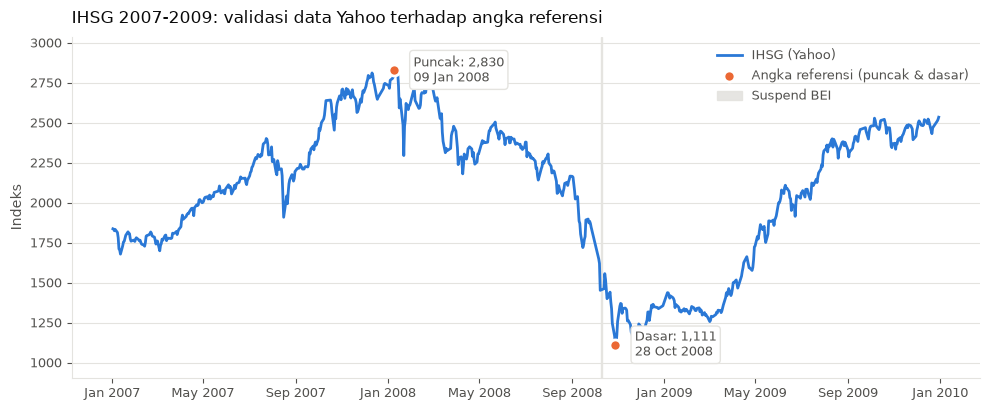

In [9]:
fig = plots.plot_jkse_2008(tgt["Close"], ref_2008) if ref_2008 else None

## 6. Kualitas data Open ^JKSE

Modul gap pembukaan (close t → open t+1) dan intraday (open → close) hanya dipakai kalau data Open layak. Empat cek:
1. **Open kosong** atau ≤ 0.
2. **Open di luar rentang Low–High**: secara definisi mustahil.
3. **Open = Close kemarin**: jebakan paling umum di data indeks Asia. Open diisi harga penutupan sebelumnya, sehingga gap pembukaan selalu nol secara palsu.
4. **OHLC datar** (Open = High = Low = Close): kolom OHLC diisi dari Close saja.

Hasil yang mungkin:
- Semua cek lolos → `gap_intraday`.
- Hanya lolos sejak tahun tertentu (minimal 5 tahun) → `gap_intraday_partial`.
- Selain itu → fallback `close_to_close`, dan keterbatasannya ditulis di README.

In [10]:
open_overall, open_per_year = q.open_quality(tgt)
open_decision = q.open_module_decision(open_overall, open_per_year, qcfg["open_checks"], qcfg["min_years_open_module"])
display(pd.Series(open_overall).round(2).to_frame("keseluruhan (%)").T)
display(Markdown(f"**Keputusan:** `{open_decision['mode']}` — {open_decision['reason']}"))
open_per_year.round(2)

,missing,outside_range,open_eq_prev_close,flat_bar,n_days
keseluruhan (%),0.0,0.0,7.57,0.1,4798.0


**Keputusan:** `close_to_close` — Kualitas Open tidak memadai (Open = Close kemarin 7.6% (batas 5.0%)) -> fallback ke close-to-close; keterbatasan dicatat di README

,n_days,missing,outside_range,open_eq_prev_close,flat_bar
year,,,,,
2007,246,0.0,0.0,0.00,0.00
2008,236,0.0,0.0,0.42,0.00
2009,240,0.0,0.0,20.42,0.00
2010,245,0.0,0.0,0.00,0.00
2011,247,0.0,0.0,0.40,0.00
2012,246,0.0,0.0,0.41,0.00
2013,244,0.0,0.0,0.00,0.00
2014,242,0.0,0.0,0.41,0.00
2015,244,0.0,0.0,0.00,0.00


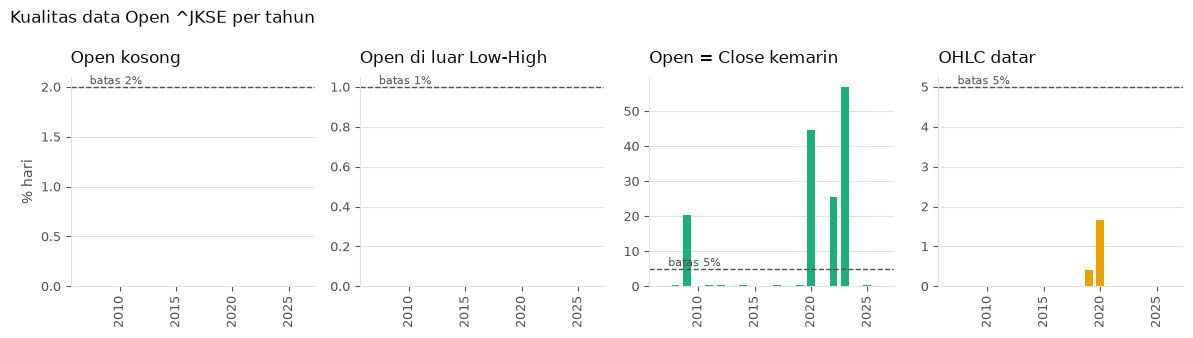

In [11]:
fig = plots.plot_open_quality(open_per_year, qcfg["open_checks"], label)

## 7. Simpan hasil untuk Phase 2

`reports/phase1/decisions.json` berisi periode analisis, mode return, dan jumlah dugaan bad tick per seri. Phase 2 membaca file ini, jadi keputusannya tidak perlu diketik ulang. File di `reports/` kecil dan di-commit sebagai jejak audit.

In [12]:
out_dir = output_dir(cfg, "reports", "phase1")
paths = q.save_phase1_outputs(out_dir, quality, moves, sanity, open_per_year, start_decision, open_decision, target_id)
[str(p.relative_to(PROJECT_ROOT)) for p in paths]

['reports/phase1/data_quality.csv',
 'reports/phase1/large_moves.csv',
 'reports/phase1/sanity_check_2008.csv',
 'reports/phase1/open_quality_by_year.csv',
 'reports/phase1/decisions.json']

## Ringkasan insight

Ringkasan di bawah dibangun otomatis dari hasil di atas, jadi selalu sesuai dengan data terakhir yang didownload.

In [13]:
display(Markdown(q.phase1_summary(quality, start_decision, sanity, open_decision, moves, label)))

### Ringkasan Phase 1

- **Periode analisis:** ^JKSE tersedia sejak 02 Jan 2007 dan 2007-2009 lengkap -> analisis mulai 01 Jan 2007 (GFC 2008 tercakup).
- **Kualitas data:** 6 dari 12 seri lolos semua cek.
  - iShares MSCI EM (EEM): 3 dugaan bad tick
  - Nifty 50 (^NSEI): mulai 2007-09-17
  - Hang Seng (^HSI): 1 dugaan bad tick
  - Brent (BZ=F): mulai 2007-07-30; gap 17 hari s/d 2009-05-01
  - USD/IDR (IDR=X): gap 26 hari s/d 2008-08-26; 8 dugaan bad tick
  - iShares MSCI Indonesia (EIDO): mulai 2010-05-07; 1 dugaan bad tick
- **Dugaan bad tick** (gerakan besar yang langsung berbalik): USDIDR (8), EEM (3), EIDO (1), HSI (1). Dibersihkan di Phase 2 dengan aturan yang sudah dikunci di README.
- **Sanity check 2008:** 5 dari 6 cek PASS.
  - Penurunan harian 2008-10-06: FAIL — dibanding close 26 Sep 2008
- **Data Open ^JKSE:** Kualitas Open tidak memadai (Open = Close kemarin 7.6% (batas 5.0%)) -> fallback ke close-to-close; keterbatasan dicatat di README.

**Langkah berikutnya, Phase 2/7 (alignment & returns):**
- Buang dugaan bad tick dengan aturan yang dikunci di README.
- Uji ulang USD/IDR dengan aturan ≥ 0,300 yang sudah dikunci.
- Perlakukan hari suspend sebagai libur.
- Hitung log return harian dan mingguan di tanggal yang sama-sama buka, plus IHSG versi USD.
- Kalau `return_mode` mengizinkan, pecah return jadi gap pembukaan dan intraday.

## Lampiran Teknis: grafik tambahan

Sel di bawah hanya **menampilkan hasil yang sudah ada**: membaca `reports/` dan `data/processed` lewat `src/report.py`, tanpa analisis atau parameter baru. Dipakai oleh `scripts/build_notebook_report.py` (Lampiran Teknis PDF).

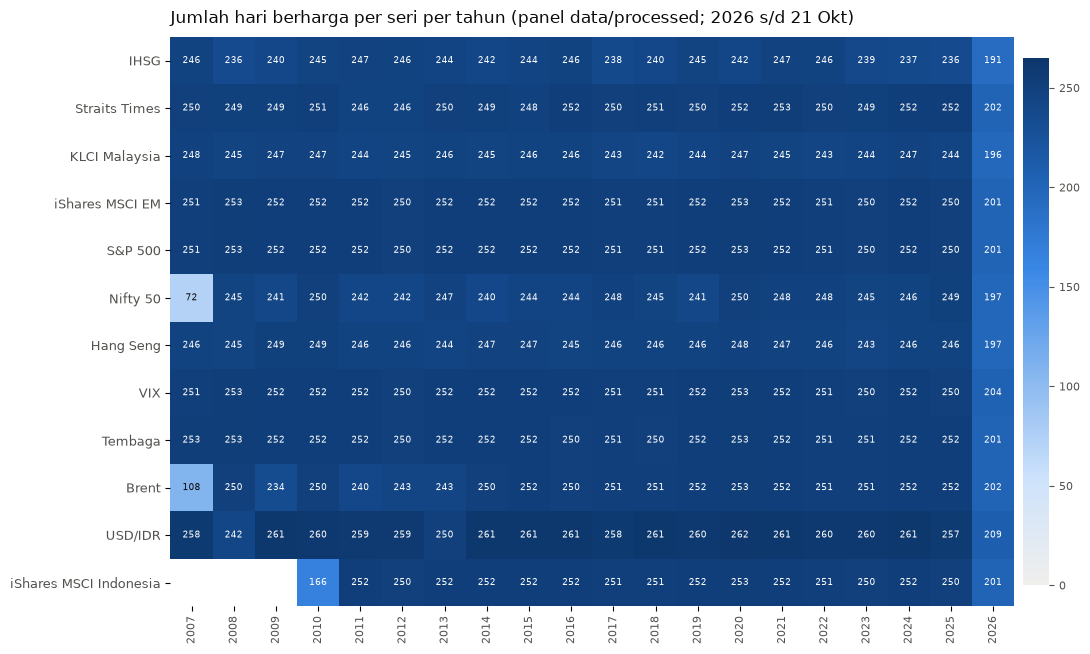

In [ ]:
from src import report
report.show("availability")